# III. Evolution du comportement d'achat

**Objectif**: Comprendre comment le comportement d'achat varie selon le profil du client (occasionnel, typique, fidèle) et identifier les produits qui génèrent de la récurrence.

**Questions à traiter**:

1. Comment évoluent les quantités d'achat selon le segment client ?
2. Quel est le taux de réachat global et par segment ?
3. Quels sont les produits les plus rachetés ?

**Impact business attendu**:
Identifier à quel moment les clients deviennent fidèles pour concentrer les actions de rétention sur les commandes critiques.

## Setup

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('..')

from src.data_loader import get_data
from src.features import enrich_dataframe
from src.features import reorder_rate_by_group, reorder_evolution

# Style global — palette sur mesure
sns.set_theme(style="whitegrid", font_scale=1)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "#fafafa",
    "figure.facecolor": "white",
})

COLORS = {
    "occasionnel": "#a8bfc1",
    "typique":     "#4290ba",
    "fidèle":      "#1b3a4b",
    "accent":      "#3cc494",
    "grey":        "#6b7280",
}
PAL_SEGMENTS = [COLORS["occasionnel"], COLORS["typique"], COLORS["fidèle"]]

# Chargement
data = get_data(raw_dir="../data/raw/",processed_path="../data/processed/merged_orders.parquet")
data = enrich_dataframe(data)
print(f"Dataset: {data.shape[0]:,} lignes, {data.shape[1]:,} colonnes")
data.head(3)


Chargement depuis le cache .parquet
Dataset: 32,434,489 lignes, 21 colonnes


,order_id,product_id,add_to_cart_order,reordered,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,...,department_id,aisle,department,user_total_orders,customer_segment,cart_size,dept_per_order,aisles_per_order,day_name,hour_period
0,2,33120,1,1,202279,3,5,9,8.0,Organic Egg Whites,...,16,eggs,dairy eggs,8,typique,9,3,8,Vendredi,Matin
1,2,28985,2,1,202279,3,5,9,8.0,Michigan Organic Kale,...,4,fresh vegetables,produce,8,typique,9,3,8,Vendredi,Matin
2,2,9327,3,0,202279,3,5,9,8.0,Garlic Powder,...,13,spices seasonings,pantry,8,typique,9,3,8,Vendredi,Matin


## Vérification rapide de la segmentation

Avant d'analyser =, on vérifie que les 3 segments sont bien répartis et cohérents avec les quartiles observés dans le notebook 01.

### Distribution des utilisateurs par segment

In [5]:
users = data.groupby("user_id").agg(
    segment=("customer_segment", "first"),
    total_orders=("user_total_orders", "first")
).reset_index()

print("Répartition des utilisateurs par segment :")
print(users["segment"].value_counts().sort_index())
print(f"\nTotal : {len(users):,} utilisateurs")

Répartition des utilisateurs par segment :
segment
occasionnel    73591
typique        84808
fidèle         47810
Name: count, dtype: int64

Total : 206,209 utilisateurs


## 1- Comment évoluent les quantités d'achat selon le segment client ?

On cherche à savoir si les clients fidèles commandent plus d'articles par commandes que les occasionnels, et si la taille du panier évolue au fil des commandes.

L'objectif serait de mettre en place des cartes de fidélité afin de récompenser la fidélité de la clientèle, mais inciterait également à acheter plus.

In [6]:
# Statistiques descriptives de la taille du panier par segment
orders_level = data.groupby(["order_id", "customer_segment", "order_number"]).agg(
    cart_size =("product_id", "count")
).reset_index()

orders_level.groupby("customer_segment")["cart_size"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
occasionnel,314243.0,9.7,7.4,1.0,4.0,8.0,13.0,101.0
typique,1000376.0,10.0,7.5,1.0,5.0,8.0,14.0,121.0
fidèle,1900255.0,10.2,7.5,1.0,5.0,8.0,14.0,145.0


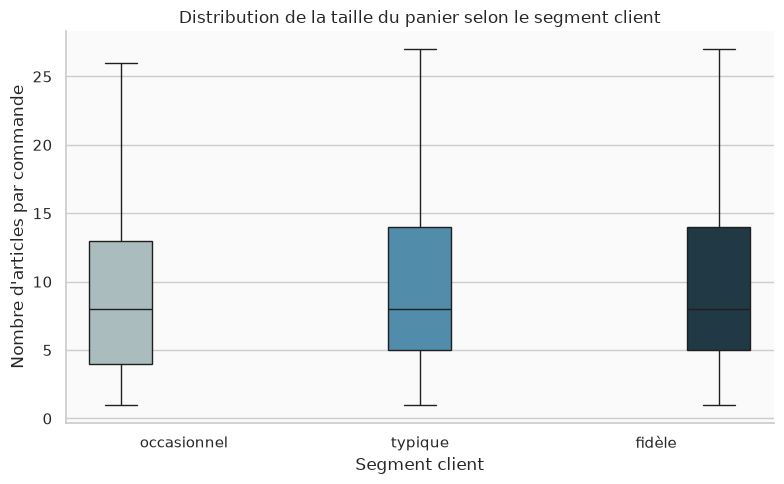

In [7]:
# Visualisation 1: Box plot, distribution de la taille du panier par segment
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=orders_level,
    x="customer_segment",
    y="cart_size",
    hue="customer_segment",
    palette=PAL_SEGMENTS,
    legend=False,
    showfliers=False,
    ax=ax
)

ax.set_xlabel("Segment client")
ax.set_ylabel("Nombre d'articles par commande")
ax.set_title("Distribution de la taille du panier selon le segment client")

plt.tight_layout()
plt.show()

### Interprétation

D'après les calculs, les trois segments présentent un comportement d'achat homogène en termees de taille de panier.

La **médiane** est identique, 8 articles, quel que soit le segment. L'écart entre occasionnels et fidèles n'est que de **+0.5 article en moyenne**, soit une différence de ~5 %, mais **négligeable en pratique**.

On peut déduire que la fidélité se traduit par une fréquence de commande plus élevée, et non par des paniers plus gros.
Un client fidèle ne remplit pas plus son panier, mais il revient simplement plus souvent.

### Implication business : 

un programme de fidélité classique (carte à points sur le montant) aurait un impact limité puisque la taille du panier est stable. Il serait plus pertinent de **récompenser la fréquence** plutôt que le volume par commande.

Ce graphique en barres rend visible ce que le boxplot masque : les trois barres sont quasi identiques, ce qui renforce visuellement le constat que la fidélité n'augmente pas la taille du panier.

## 2- Quel est le taux de réachat global et par segment client ?

La colonne reordered vaut 1 si le client a déjà commandé "ce produit avant", sinon 0. Un taux élevé signifi que les client rachètent les mêmes produits, signe d'habitudes et de fidélité produit.

In [8]:
# Taux de réachat global
global_reorder = data["reordered"].mean()
print(f"Taux de réachat moyen: {global_reorder:.1%}")

# Par segment
reorder_by_segment = (
    data.groupby("customer_segment", observed=True)["reordered"]
    .mean()
    .reset_index()
    .rename(columns={"reordered": "taux_reachat"})
)
reorder_by_segment["taux_reachat_pct"] = (reorder_by_segment["taux_reachat"] * 100).round(1)
reorder_by_segment

Taux de réachat moyen: 59.0%


,customer_segment,taux_reachat,taux_reachat_pct
0,occasionnel,0.282336,28.2
1,typique,0.485731,48.6
2,fidèle,0.692028,69.2


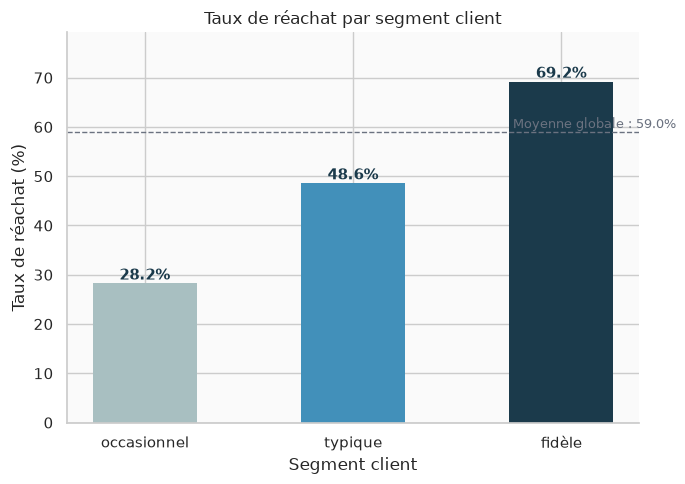

In [9]:
# Visualisation : taux de réachat par segment
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    reorder_by_segment["customer_segment"].astype(str),
    reorder_by_segment["taux_reachat"] * 100,
    color=PAL_SEGMENTS,
    edgecolor="none",
    width=0.5
)

# Ligne de moyenne globale
ax.axhline(y=global_reorder * 100, color=COLORS["grey"], linestyle="--", linewidth=1)
ax.text(
    2.55, global_reorder * 100 + 0.8,
    f"Moyenne globale : {global_reorder:.1%}",
    color=COLORS["grey"], fontsize=9, ha="right"
)

# Annotations sur les barres
for bar, val in zip(bars, reorder_by_segment["taux_reachat_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
        f"{val}%", ha="center", fontsize=11, fontweight="bold", color=COLORS["fidèle"]
    )

ax.set_xlabel("Segment client")
ax.set_ylabel("Taux de réachat (%)")
ax.set_title("Taux de réachat par segment client")
ax.set_ylim(0, max(reorder_by_segment["taux_reachat"] * 100) + 10)

plt.tight_layout()
plt.show()

### Interprétation:

Le taux de réachat varie entre segment, avec une moyenne de 59% de taux de réachat.
Les clients occasionnels ont un taux de réachat de 28.2% (bien en dessous de la moyenne)
Les clients typiques ont un taux de réachat se rapprochant de la moyenne, soit 48,6%.
Et les client fidèles ont un taux de réachat supérieur à la moyenne, soit 69,2 %.

Nous avons constaté précédemment que la taille du panier était quasi identique entre segments (~8 articles). Le taux de réachat révèle une différence significative : un client fidèle rachète 7 produits sur 10* qu'il a déjà commandés, contre moins de 3 sur 10 chez un occasionnel.

Cela confirme le constat précédent: la fidélité se traduit par la récurrence, et non par le volume.

### Implication business

Nous pouvons emmettre 3 hypothèses concernant cette analyse:

- **Hypothèse 1: Produits ancres** : certains produits à fort taux de réachat "verrouillent" le client sur la plateforme (produits du quotidien indispensables).
- **Hypothèse 2: Satisfaction et fidélisation** : le client revient par habitude ou satisfaction globale du service, indépendamment des produits spécifiques.
- **Hypothèse 3: Effet d'habitude de commande** : les clients fidèles utilisent la fonction "recommander" ou reconstituent un panier type par automatisme, ce qui gonfle mécaniquement le taux de réachat.


## 3- Quels sont les produits les plus rachetés ?

On identifie les produits ayant le plus de récurrence d'achat: ceux que les clients rachètent commande après commande.

In [10]:
# Top 20 des produits les plus rachetés (en volume)
top_reordered = (
    data[data["reordered"] == 1]
    .groupby("product_name")
    .size()
    .nlargest(20)
    .reset_index(name="nb_reorders")
)
top_reordered

,product_name,nb_reorders
0,Banana,221490
1,Bag of Organic Bananas,175093
2,Organic Strawberries,114119
3,Organic Baby Spinach,103938
4,Organic Hass Avocado,94779
5,Organic Avocado,74410
6,Organic Whole Milk,63827
7,Large Lemon,59352
8,Organic Raspberries,58474
9,Strawberries,55346


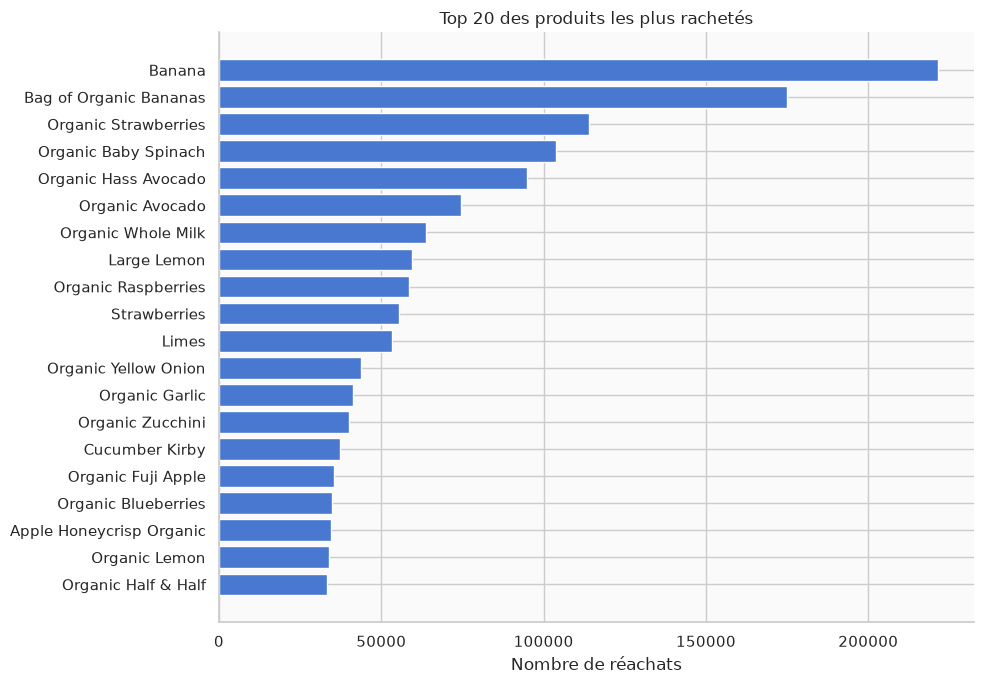

In [11]:
# Visualisation: Bar chart horizontal
fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_reordered["product_name"][::-1],
    top_reordered["nb_reorders"][::-1],
    color=sns.color_palette("muted")[0]
)

ax.set_xlabel("Nombre de réachats")
ax.set_title("Top 20 des produits les plus rachetés")

plt.tight_layout()
plt.show()


## Interprétation
Les bananes sont les produits les plus revendus en terme de quantité dépassant significativement les autres produits, suivi des sacs de bananes.

In [12]:
# Complément : taux de réachat par produit, parmi les produits vendus supérieur à 1000 fois.
# Un produit peut être très vendu mais peu racheté, ou peu vendu mais toujours racheté.

product_stats = (
    data.groupby("product_name")
    .agg(
        total_ventes=("reordered", "count"),
        nb_reorders=("reordered", "sum"),
    )
)
product_stats["taux_reachat_%"] = (product_stats["nb_reorders"]*100) / product_stats["total_ventes"]

# Filtrer les produits avec assez de voliumes pour être significatifs
popular = product_stats[product_stats["total_ventes"] >= 1000].sort_values("taux_reachat_%", ascending=False)


print("Top 15 taux de réachat les plus élevé (min 1000 ventes) :")
popular.head(15).round(2)

Top 15 taux de réachat les plus élevé (min 1000 ventes) :


,total_ventes,nb_reorders,taux_reachat_%
product_name,,,
Half And Half Ultra Pasteurized,1620,1413,87.22
Organic Lactose Free Whole Milk,4683,4025,85.95
Whole Organic Omega 3 Milk,5061,4348,85.91
Organic Homogenized Whole Milk,2203,1883,85.47
"Milk, Organic, Vitamin D",11252,9599,85.31
Organic Reduced Fat Milk,19892,16964,85.28
Goat Milk,2980,2534,85.03
Banana,262750,221490,84.30
Organic Lowfat 1% Milk,8268,6961,84.19


### Interprétation

Le top 15 des produits les plus rachetés (min. 500 ventes) révèle un profil très marqué :

**Laits** : 13 des 15 produits sont des laits ou crèmes. Le lait est un produit de consommation quotidienne à cycle de réachat naturellement court. Il se termine vite, on le rachète par nécessité. La Banana (seul produit non-laitier du top 15, et de loin le plus vendu avec 262 750 ventes) suit la même logique de périssabilité rapide.

**Surreprésentation du bio** : 11 des 15 produits portent la mention "Organic". Cela peut signaler que les clients bio sont structurellement plus fidèles à la plateforme, ou que le bio est un critère de rachat en soi (on rachète le "même" lait bio, là où un client non-bio pourrait alterner entre marques).

**Taux resserrés** : tous les taux se situent entre **83 % et 87 %**. L'écart entre le 1er et le 15ème n'est que de 4 points. Cela suggère un plafond naturel de réachat autour de 85 % pour les produits du quotidien.

#### Hypothèses à confronter

- **Effet catégorie** : le réachat élevé est lié au type de produit (périssable, quotidien) et non à la fidélité client. Un occasionnel qui achète du lait le rachètera aussi.
- **Profil client bio** : les acheteurs de produits bio seraient intrinsèquement plus fidèles.
- **Effet de commande rapide** : la plateforme propose peut-être une fonctionnalité de "re-commander" qui favorise mécaniquement les produits basiques.

## Analyse croisée : validation des hypothèses

Les trois questions visent à discriminer entre les hypothèse posées.

### H1. Reachat par département x segment : top 8 département par volume

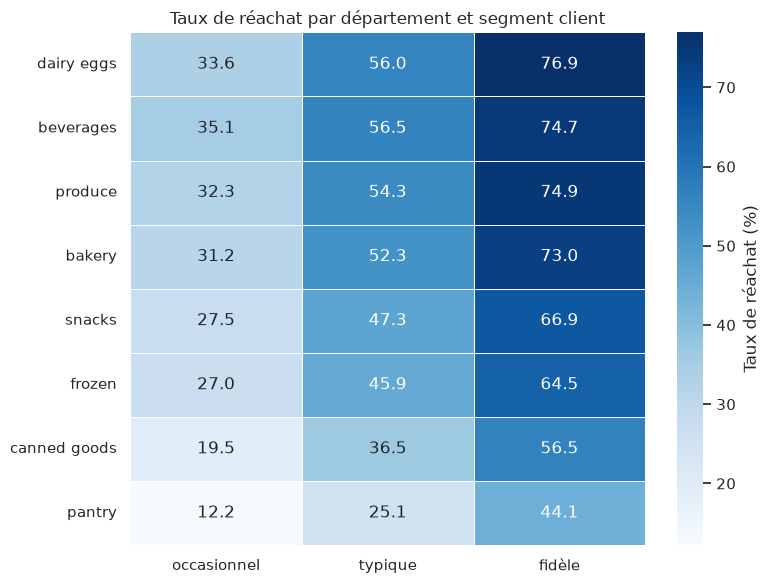

In [13]:
top_depts = data["department"].value_counts().head(8).index.tolist()
dept_segment = reorder_rate_by_group(
    data[data["department"].isin(top_depts)],
    ["department", "customer_segment"]
)

# Heatmap
pivot = dept_segment.pivot(index="department", columns="customer_segment", values="taux_reachat")
pivot = pivot[["occasionnel", "typique", "fidèle"]] 
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    pivot * 100,
    annot=True, fmt=".1f", cmap="Blues",
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "Taux de réachat (%)"},
    ax=ax
)
ax.set_title("Taux de réachat par département et segment client")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Interprétation

La heatmap révèle **deux effets simultanés** :

- **Effet client (lecture en colonnes)** : pour chaque département, le taux de réachat croît systématiquement d'occasionnel à fidèle. L'écart occasionnel/fidèle est d'environ **+40 points** quelle que soit la catégorie. Ce n'est pas un effet propre à un département, c'est un comportement global du client.

- **Effet catégorie (lecture en lignes)** : certains départements génèrent structurellement plus de réachat que d'autres. Dairy eggs (76.9 % chez les fidèles) et beverages (74.7 %) dominent, tandis que pantry (44.1 %) reste bas même chez les fidèles. Les produits périssables du quotidien sont rachetés plus souvent, quel que soit le profil client.

**Verdict sur l'hypothèse 1** : l'effet catégorie existe (les périssables sont plus rachetés), mais il n'explique pas uniquement le réachat. L'effet client domine. Un client fidèle rachète davantage dans toutes les catégories, y compris les moins périssables.

## H2. Réachat organic vs non-organic par segment (test profil bio)

Cette analyse vise à déterminer sur les acheteurs bio sont intrinséquement plus fidèles, on devrait voir un gap organic/non organic même au sein du même groupe.

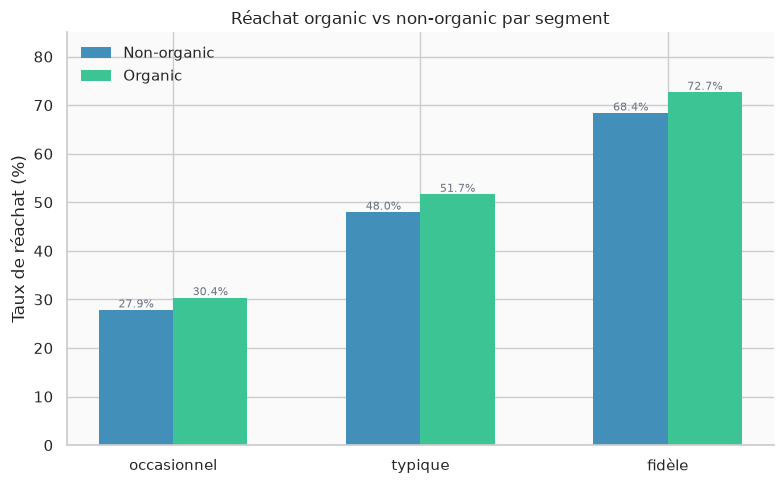

In [14]:
# Flag organic basé sur le nom du produit
data["is_organic"] = data["product_name"].str.contains(
    r"\borganic\b", case=False, na=False
).astype(int)

organic_segment = reorder_rate_by_group(data, ["is_organic", "customer_segment"])
organic_segment["label"] = organic_segment["is_organic"].map({0: "Non-organic", 1: "Organic"})

# Grouped bar chart
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(3)
width = 0.3

for i, (label, grp) in enumerate(organic_segment.groupby("label")):
    vals = grp.sort_values("customer_segment")["taux_reachat"] * 100
    color = COLORS["accent"] if label == "Organic" else COLORS["typique"]
    bars = ax.bar(x + i * width, vals, width, label=label, color=color, edgecolor="none")
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                f"{val:.1f}%", ha="center", fontsize=8, color=COLORS["grey"])

ax.set_xticks(x + width / 2)
ax.set_xticklabels(["occasionnel", "typique", "fidèle"])
ax.set_ylabel("Taux de réachat (%)")
ax.set_title("Réachat organic vs non-organic par segment")
ax.legend(frameon=False)
ax.set_ylim(0, 85)
plt.tight_layout()
plt.show()

### Interprétatioon

Selon l'analyse, l'écart organic/non organic est plus ou moins stable mais modeste.

Le bio est un facteur indépendant mais secondaire : il ajoute 2 à 4 points de réachat quel que soit le segment. L'écart se creuse légèrement chez les fidèles (+4.3 pts vs +2.5 pts), ce qui suggère une interaction modérée entre profil bio et fidélité, sans en être le moteur principal.

**Verdict sur l'hypothèse 2** : le bio contribue marginalement au réachat. Ce n'est pas le profil bio qui crée la fidélité, mais c'est plutôt la fidélité qui s'accompagne d'un léger renforcement du choix bio.

## H3. Evolution du taux de réachat au fil des commandes (effet d'habitude)

Si le réachat augmente avec le numéro de commande, cela suggère un comportement d'habitude. Si le taux est stable dès la 2ème commande, c'est plus un trait du produit.

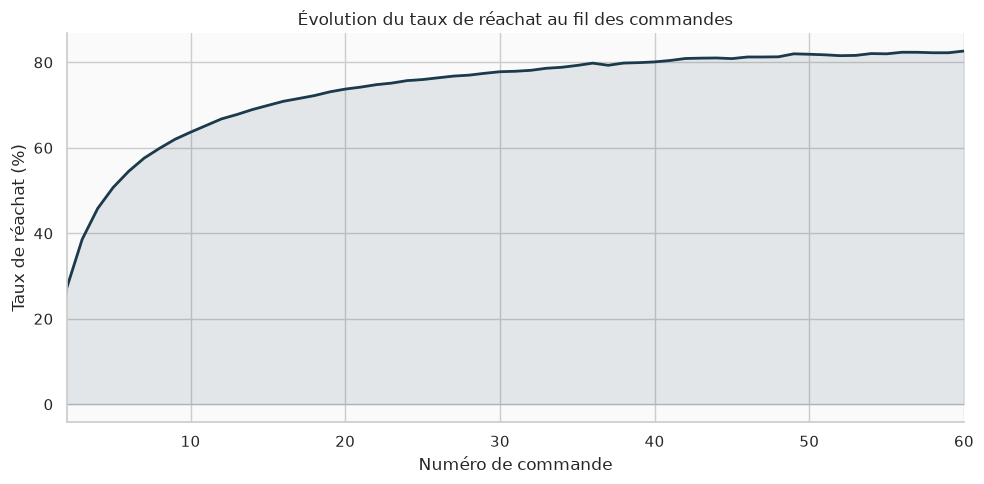

In [15]:
evolution = reorder_evolution(data)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    evolution["order_number"],
    evolution["taux_reachat"] * 100,
    color=COLORS["fidèle"], linewidth=2
)
ax.fill_between(
    evolution["order_number"],
    evolution["taux_reachat"] * 100,
    alpha=0.1, color=COLORS["fidèle"]
)

ax.set_xlabel("Numéro de commande")
ax.set_ylabel("Taux de réachat (%)")
ax.set_title("Évolution du taux de réachat au fil des commandes")
ax.set_xlim(2, 60)
plt.tight_layout()
plt.show()

### Interprétation:

La courbe montre deux phases distinctes :

- **Phase d'installation (commandes 2 à 10)** : le taux de réachat passe de ~28 % à ~65 %, soit un gain de +37 points en 8 commandes. C'est la période où le client découvre ses produits récurrents et installe ses habitudes.

- **Phase de plateau (après la commande 10-15)** : la croissance ralentit fortement. Le taux passe de 65 % à ~82 %, soit seulement +17 points sur les 50 commandes suivantes.

Le point d'inflexion se situe **autour de la 10ᵉ commande**. C'est là que la courbe passe de convexe à concave, autrement dit, c'est la commande après laquelle le gain marginal de réachat diminue. La 20ᵉ commande marque l'entrée dans le plateau de stabilisation.

**Verdict sur l'hypothèse 3** : l'effet d'habitude est confirmé. Les premières commandes sont le moment critique où le client construit son panier récurrent. Un client qui atteint la 10ᵉ commande a déjà internalisé l'essentiel de ses habitudes de réachat.

## Synthèse - Evolution du comportement d'achat

### Résultat d'analyse

Les trois analyses et leurs croisements convergent vers un modèle cohérent du comportement client sur la plateforme :

1. **La fidélité est un phénomène de fréquence, et non de volume.**
La taille du panier est stable (~8 articles) quel que soit le segment. Les fidèles ne dépensent pas plus par commande, mais ils commandent plus souvent.

2. **Le réachat est un marqueur de fidélité.**
L'écart occasionnel/fidèle se maintient sur tous les départements (+40 pts), ce qui prouve un comportement client structurel. L'effet catégorie (périssables plus rachetés) existe mais ne suffit pas à expliquer les écarts.

3. **Le bio est un signal, pas un moteur.**
Le bio semble davantage corrélé à un profil client déjà engagé qu'être une cause de fidélisation.

4. **Les 10 premières commandes sont la fenêtre critique.**
Le taux de réachat double entre la 2ème et la 10ème commande, puis se stabilise.
Si un client n'installe pas des habitudes à sa 10ème commande, il y a peu de chances qu'il le fera.


### Orientations business

Ces constats permettent de formuler trois axes d'action :

**1. Rétention rapide (commandes 3 à 10)** :
Concentrer les investissements marketing sur la fenêtre critique. Un bon de réduction ciblé à la 4ème commande, suivi d'un rappel personnalisé si le client dépasse son intervalle
habituel entre la 5ème et la 10ème.
L'objectif est de transformer un occasionnel en typique.

**2. Programme de fidélité basé sur la fréquence** :
Puisque le panier est stable mais la fréquence varie, des offres promotionnelles de type "10ème commande offerte" ou "livraison gratuite à partir de X commandes/mois" pourrait être envisagé.

**3. Disponibilité des produits ancres** :
Les dairy eggs, beverages et produce concentrent les taux de réachat les plus élevés.
Une rupture de stock sur ces catégories touche directement le cycle de réachat et risque de casser l'habitude.
Le suivi de disponibilité sur ces départements doit être prioritaire.